# British Airways – Predicting Customer Buying Behaviour
Forage Task 2 · Rehan Deshmukh

Upload `customer_booking.csv` to Colab (Files panel on the left), then run each cell.

In [1]:
# British Airways - Predicting customer buying behaviour (Forage Task 2)
import pandas as pd, numpy as np, matplotlib
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

df = pd.read_csv('customer_booking.csv', encoding='ISO-8859-1')
print(df.shape); print(df.booking_complete.value_counts(normalize=True).round(3))

(50000, 14)
booking_complete
0    0.85
1    0.15
Name: proportion, dtype: float64


In [2]:
# Feature engineering
day_map = {'Mon':1,'Tue':2,'Wed':3,'Thu':4,'Fri':5,'Sat':6,'Sun':7}
df['flight_day'] = df['flight_day'].map(day_map)
df['is_weekend'] = (df['flight_day'] >= 6).astype(int)
df['total_extras'] = df[['wants_extra_baggage','wants_preferred_seat','wants_in_flight_meals']].sum(axis=1)

accuracy: 0.762
precision: 0.336
recall: 0.604
f1: 0.431
roc_auc: 0.775


booking_origin           0.256
route                    0.148
purchase_lead            0.134
length_of_stay           0.116
flight_hour              0.092
flight_duration          0.083
flight_day               0.055
num_passengers           0.028
total_extras             0.026
wants_extra_baggage      0.015
sales_channel_Mobile     0.014
wants_preferred_seat     0.011
wants_in_flight_meals    0.011
is_weekend               0.010
trip_type_RoundTrip      0.002
trip_type_OneWay         0.001
dtype: float64


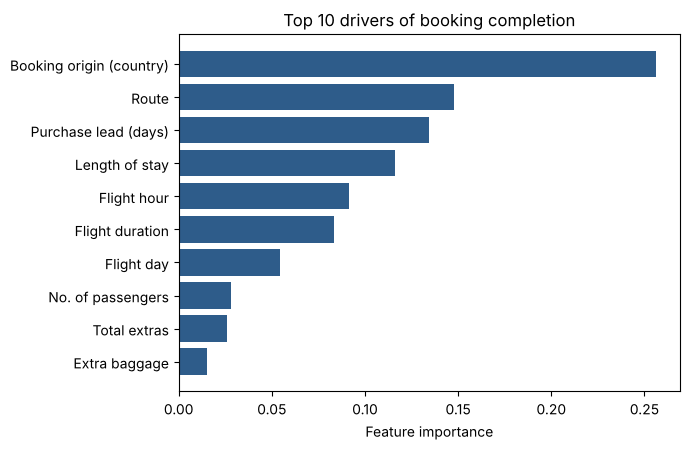

In [3]:
# Encode high-cardinality text columns by frequency, low-cardinality by one-hot
for col in ['route','booking_origin']:
    df[col] = df[col].map(df[col].value_counts(normalize=True))
df = pd.get_dummies(df, columns=['sales_channel','trip_type'], drop_first=True, dtype=int)

X = df.drop(columns='booking_complete'); y = df['booking_complete']
model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight='balanced', random_state=42, n_jobs=-1)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(model, X, y, cv=cv, scoring=['accuracy','precision','recall','f1','roc_auc'])
for k in ['accuracy','precision','recall','f1','roc_auc']:
    print(f"{k}: {scores['test_'+k].mean():.3f}")

model.fit(X, y)
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()
print(imp.sort_values(ascending=False).round(3))
names = {'purchase_lead':'Purchase lead (days)','route':'Route','flight_hour':'Flight hour','length_of_stay':'Length of stay',
 'booking_origin':'Booking origin (country)','flight_duration':'Flight duration','flight_day':'Flight day','num_passengers':'No. of passengers',
 'total_extras':'Total extras','wants_extra_baggage':'Extra baggage','wants_in_flight_meals':'In-flight meals','wants_preferred_seat':'Preferred seat',
 'is_weekend':'Weekend flight','sales_channel_Mobile':'Sales channel: mobile','trip_type_OneWay':'Trip type: one way','trip_type_RoundTrip':'Trip type: round trip'}
top = imp.tail(10).rename(index=names)
plt.figure(figsize=(7,4.6)); plt.barh(top.index, top.values, color='#2E5C8A')
plt.xlabel('Feature importance'); plt.title('Top 10 drivers of booking completion'); plt.tight_layout()
plt.show()